# Wykresy wyników OOD — detektor deepfake

Parametryzowane wykresy do rozdziału 3. **Aby przeliczyć dla innego modelu:**
zmień `MODEL_PATH` w komórce konfiguracji i wykonaj *Run All*.

Wykresy zapisują się do `model_testing/graphs/` jako PNG **i** PDF (PDF = wektor do LaTeX-a).
Wymaga GPU (≈5 min: 3 przebiegi inferencji). Nie odpalać równolegle z treningiem.

In [1]:
# === KONFIGURACJA — podmień MODEL_PATH i Run All ===
MODEL_PATH = "Models/wav2vec2_300m_not_frozen_V2_balanced_ood_v2_2.pt"  # model E6 (finalny)
MODEL_NAME = "facebook/wav2vec2-xls-r-300m"
DATASET_VERSION = 5
MAX_LEN = 64000
BATCH = 16
NUM_WORKERS = 4

# Progresja OOD AUC do wykresu słupkowego (edytowalne — wartości nagłówkowe per etap)
ABLATION = {
    "E0\noryginał": 0.43,
    "E1\nunfrozen": 0.756,
    "E4\nfrozen+LS": 0.789,
    "E5\nunfrozen+LS\n(in-dom sel.)": 0.878,
    "E6\nunfrozen+LS\n(val_ood sel.)": 0.904,
}

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Code/ i Code/model_testing/ na ścieżce
NB_DIR = Path.cwd()
CODE_DIR = NB_DIR.parent if NB_DIR.name == "model_testing" else NB_DIR
for p in (str(CODE_DIR), str(CODE_DIR / "model_testing")):
    if p not in sys.path:
        sys.path.insert(0, p)

import evalOodFromCsv as ev   # reużycie: predict, fit_temperature, eer, youden_threshold, ece, scores_from_logits
from model_training.detector import Wav2Vec2DeepfakeDetector
from model_training.datasetMethods import AudioDatasetFromCSV
from projectMethods import get_device, get_dataset_split_csv, find_project_root

ROOT = find_project_root()
GRAPHS = (CODE_DIR / "model_testing" / "graphs")
GRAPHS.mkdir(parents=True, exist_ok=True)

# === Jednolity, JASNY styl pod LaTeX (Times New Roman) ===
# Wymusza biały rysunek niezależnie od motywu IDE / wcześniejszego stanu sesji
# (poprzednie czarne tło brało się z odziedziczonego 'dark_background').
plt.style.use("default")
plt.rcParams.update({
    # białe tło wszędzie (rysunek, osie, zapis do pliku)
    "figure.facecolor": "white",
    "axes.facecolor":   "white",
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    # rozdzielczość
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    # czcionka Times New Roman — spójna z tekstem pracy w LaTeX-u
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",   # matematyka w stylu Timesa
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    # delikatna siatka pozioma + czyste osie
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#dddddd",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    # czytelne, ciemne kolory tekstu/osi
    "text.color": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#333333",
    "ytick.color": "#333333",
    # ramka legendy
    "legend.frameon": True,
    "legend.framealpha": 0.95,
    "legend.edgecolor": "#cccccc",
})

# wspólna paleta (spójna we wszystkich wykresach)
C_BONA  = "#2a7de1"   # bonafide / wynik finalny
C_SPOOF = "#e15a2a"   # spoof / deepfake
C_GREY  = "#9aa0a6"   # tło / etapy pośrednie

def save(fig, name):
    """Zapis PNG (podgląd) + PDF (wektor do LaTeX-a) na białym tle."""
    for ext in ("png", "pdf"):
        fig.savefig(GRAPHS / f"{name}.{ext}", facecolor="white", bbox_inches="tight")
    print("zapisano:", name)

In [3]:
# === Model + predykcje (in-domain val, val_ood, test) ===
device = get_device()
csv = str(get_dataset_split_csv(DATASET_VERSION))

mp = Path(MODEL_PATH)
if not mp.is_absolute():
    mp = ROOT / MODEL_PATH
assert mp.exists(), f"Brak modelu: {mp}"
print("Model:", mp.name)

model = Wav2Vec2DeepfakeDetector(model_name=MODEL_NAME, freeze_encoder=False,
                                 pooling_mode="mean", dropout=0.3)
model.load_state_dict(torch.load(mp, map_location=device))
model.to(device)

def make_loader(split):
    ds = AudioDatasetFromCSV(csv_file=csv, split=split, max_length=MAX_LEN)
    dl = DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS,
                    pin_memory=(device.type == "cuda"))
    return ds, dl

_, val_loader = make_loader("val_ood")
_, test_loader = make_loader("test")
_, ind_loader = make_loader("val")   # in-domain — do kontrastu ROC

val_logits, val_y = ev.predict(model, val_loader, device)
test_logits, test_y = ev.predict(model, test_loader, device)
ind_logits, ind_y = ev.predict(model, ind_loader, device)

CUDA GPU: NVIDIA GeForce RTX 4080 SUPER
CUDA Memory: 16.0 GB
Model: wav2vec2_300m_not_frozen_V2_balanced_ood_v2_2.pt
predykcja: 100%|██████████| 2599/2599 [02:44<00:00, 15.79it/s]


In [4]:
# === Score'y, temperatura, progi ===
val_s,  test_s,  ind_s  = (ev.scores_from_logits(x) for x in (val_logits, test_logits, ind_logits))
T = ev.fit_temperature(val_logits, val_y)
val_sT, test_sT = ev.scores_from_logits(val_logits, T), ev.scores_from_logits(test_logits, T)

thr_raw = ev.youden_threshold(val_y, val_s)     # próg na surowych score'ach
thr_T   = ev.youden_threshold(val_y, val_sT)    # próg po temperaturze

test_auc = roc_auc_score(test_y, test_s)
test_eer = ev.eer(test_y, test_s)[0]
ece_before, ece_after = ev.ece(test_s, test_y), ev.ece(test_sT, test_y)
print(f"TEST AUC={test_auc:.4f}  EER={test_eer:.4f}")
print(f"T={T:.3f}  ECE {ece_before:.4f} -> {ece_after:.4f}  | prog surowy={thr_raw:.3f} / po T={thr_T:.3f}")

TEST AUC=0.9043  EER=0.1709
T=3.590  ECE 0.2379 -> 0.1560  | prog surowy=0.978 / po T=0.742


In [5]:
# === Mapowanie plik -> mówca (z meta.csv In-the-Wild), w kolejności CSV ===
df = pd.read_csv(csv)
meta = pd.read_csv(ROOT / "AudioFiles" / "Datasets" / "V2" / "raw" / "test" / "In-The-Wild" / "meta.csv")
stem2spk = {Path(str(r.file)).stem: str(r.speaker) for r in meta.itertuples(index=False)}

def speakers_for(split):
    paths = df[df["split"] == split]["file_path"].tolist()  # ta sama kolejność co w AudioDatasetFromCSV
    return np.array([stem2spk.get(Path(p).stem, "?") for p in paths])

val_spk, test_spk = speakers_for("val_ood"), speakers_for("test")
print("mówcy: val_ood", len(set(val_spk)), "| test", len(set(test_spk)))

mówcy: val_ood 27 | test 27


## 1. Progresja OOD AUC (E0 → E6)

zapisano: 01_ablacja_ood_auc


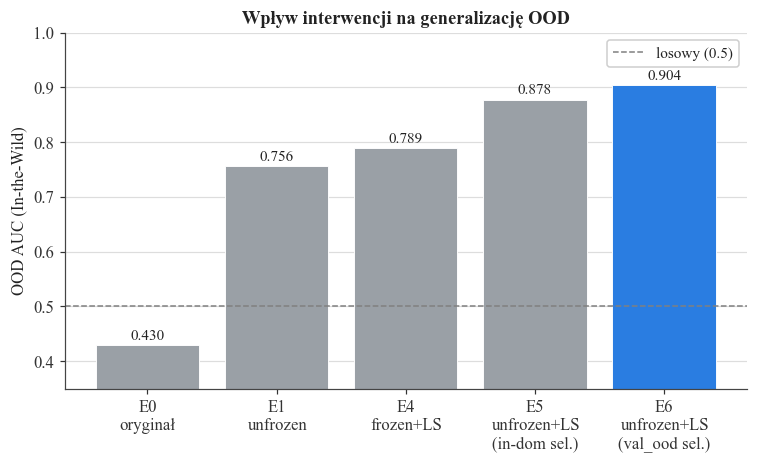

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
names, vals = list(ABLATION.keys()), list(ABLATION.values())
colors = [C_GREY] * (len(vals) - 1) + [C_BONA]
bars = ax.bar(names, vals, color=colors, edgecolor="white", linewidth=0.6)
ax.axhline(0.5, ls="--", c="gray", lw=1, label="losowy (0.5)")
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylabel("OOD AUC (In-the-Wild)"); ax.set_ylim(0.35, 1.0)
ax.set_title("Wpływ interwencji na generalizację OOD"); ax.legend()
save(fig, "01_ablacja_ood_auc"); plt.show()

## 2. Krzywe ROC — in-domain vs OOD (luka generalizacji)

zapisano: 02_roc_indomain_vs_ood


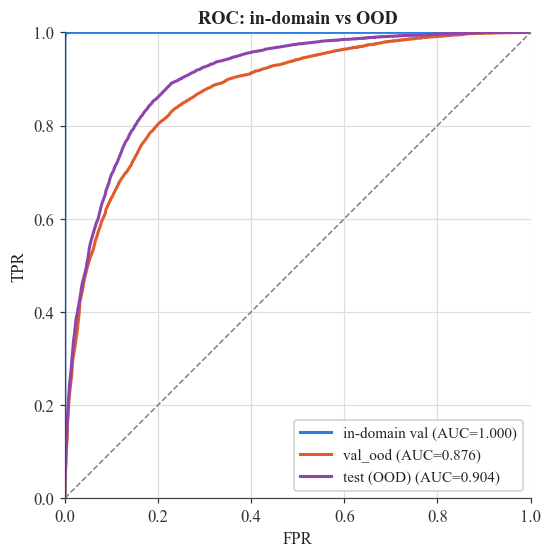

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
roc_styles = [(ind_s, ind_y, "in-domain val", C_BONA),
              (val_s, val_y, "val_ood", C_SPOOF),
              (test_s, test_y, "test (OOD)", "#8e44ad")]
for s, y, lab, col in roc_styles:
    fpr, tpr, _ = roc_curve(y, s)
    ax.plot(fpr, tpr, label=f"{lab} (AUC={roc_auc_score(y, s):.3f})", color=col, lw=2)
ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
ax.grid(True, axis="both", color="#dddddd", lw=0.8)   # ROC czyta się lepiej z pełną siatką
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.set_title("ROC: in-domain vs OOD")
ax.legend(loc="lower right")
save(fig, "02_roc_indomain_vs_ood"); plt.show()

## 3. Rozkład P(bonafide) na teście + progi

zapisano: 03_histogram_scores


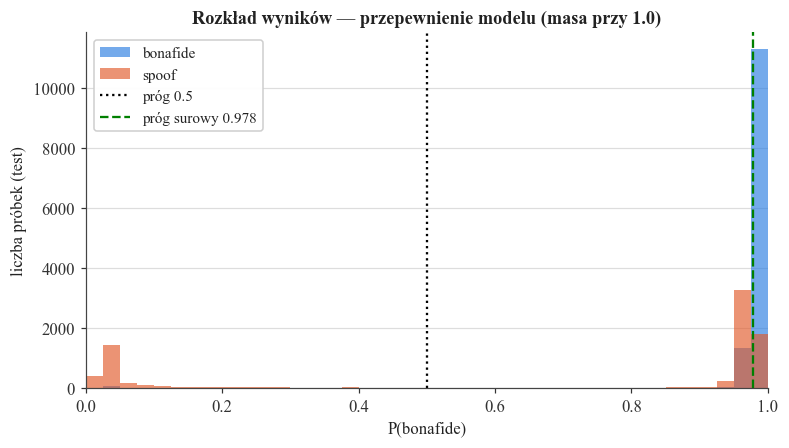

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
bins = np.linspace(0, 1, 41)
ax.hist(test_s[test_y == 1], bins=bins, alpha=0.65, label="bonafide", color=C_BONA)
ax.hist(test_s[test_y == 0], bins=bins, alpha=0.65, label="spoof", color=C_SPOOF)
ax.axvline(0.5, ls=":", c="black", label="próg 0.5")
ax.axvline(thr_raw, ls="--", c="green", label=f"próg surowy {thr_raw:.3f}")
ax.set_xlim(0, 1)
ax.set_xlabel("P(bonafide)"); ax.set_ylabel("liczba próbek (test)")
ax.set_title("Rozkład wyników — przepewnienie modelu (masa przy 1.0)"); ax.legend()
save(fig, "03_histogram_scores"); plt.show()

## 4. AUC per mówca (wariancja na In-the-Wild, 54 mówców)

zapisano: 04_auc_per_mowca


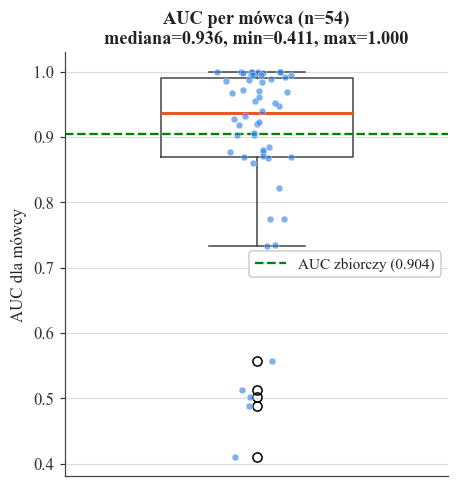

In [9]:
all_s = np.concatenate([val_s, test_s]); all_y = np.concatenate([val_y, test_y])
all_spk = np.concatenate([val_spk, test_spk])
per_spk = []
for spk in sorted(set(all_spk)):
    m = all_spk == spk
    if len(set(all_y[m].tolist())) == 2:
        per_spk.append(roc_auc_score(all_y[m], all_s[m]))
per_spk = np.array(per_spk)
fig, ax = plt.subplots(figsize=(4.5, 5))
ax.boxplot(per_spk, vert=True, widths=0.5,
           medianprops=dict(color=C_SPOOF, lw=2),
           boxprops=dict(color="#444444"), whiskerprops=dict(color="#444444"),
           capprops=dict(color="#444444"))
ax.scatter(np.random.RandomState(0).normal(1, 0.04, len(per_spk)), per_spk,
           alpha=0.6, s=20, color=C_BONA, edgecolor="white", linewidth=0.4, zorder=3)
ax.axhline(test_auc, ls="--", c="green", label=f"AUC zbiorczy ({test_auc:.3f})")
ax.set_xticks([]); ax.set_ylabel("AUC dla mówcy")
ax.set_title(f"AUC per mówca (n={len(per_spk)})\nmediana={np.median(per_spk):.3f}, min={per_spk.min():.3f}, max={per_spk.max():.3f}")
ax.legend()
save(fig, "04_auc_per_mowca"); plt.show()

## 5. Macierz pomyłek (test, próg skalibrowany po temperaturze)

zapisano: 05_macierz_pomylek


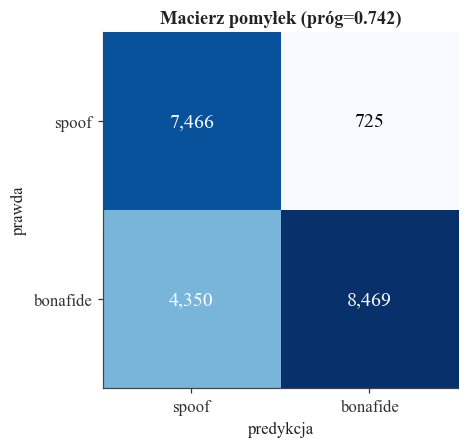

TN, FP, FN, TP = [7466  725 4350 8469]


In [10]:
pred = (test_sT >= thr_T).astype(int)
cm = confusion_matrix(test_y, pred, labels=[0, 1])  # [[TN, FP], [FN, TP]] ; 0=spoof, 1=bonafide
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.grid(False)   # heatmapa — bez siatki
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["spoof", "bonafide"]); ax.set_yticks([0, 1], ["spoof", "bonafide"])
ax.set_xlabel("predykcja"); ax.set_ylabel("prawda")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=13)
ax.set_title(f"Macierz pomyłek (próg={thr_T:.3f})")
save(fig, "05_macierz_pomylek"); plt.show()
print("TN, FP, FN, TP =", cm.ravel())

## 6. Diagram niezawodności (kalibracja przed/po temperaturze)

zapisano: 06_reliability_ece


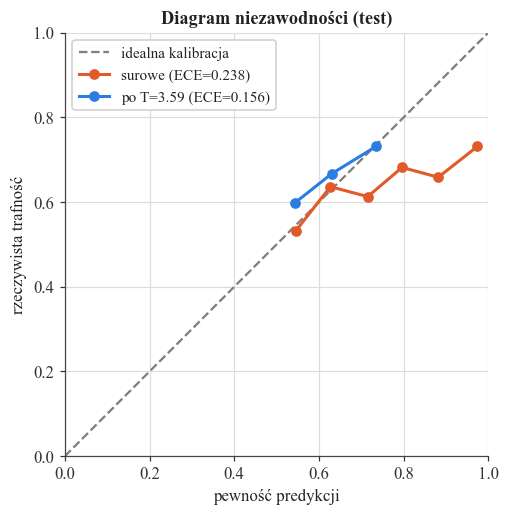

In [11]:
def reliability(scores, y, n_bins=12):
    pred = (scores >= 0.5).astype(int)
    conf = np.where(pred == 1, scores, 1 - scores)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for i in range(n_bins):
        m = (conf > edges[i]) & (conf <= edges[i+1])
        if m.sum():
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return np.array(xs), np.array(ys)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], ls="--", c="gray", label="idealna kalibracja")
for s, lab, ec in [(test_s, f"surowe (ECE={ece_before:.3f})", C_SPOOF),
                   (test_sT, f"po T={T:.2f} (ECE={ece_after:.3f})", C_BONA)]:
    xs, ys = reliability(s, test_y)
    ax.plot(xs, ys, "o-", color=ec, label=lab, lw=2)
ax.grid(True, axis="both", color="#dddddd", lw=0.8)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("pewność predykcji"); ax.set_ylabel("rzeczywista trafność")
ax.set_title("Diagram niezawodności (test)"); ax.legend(loc="upper left")
save(fig, "06_reliability_ece"); plt.show()